In [54]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

a = A1/A0         = 0.35 +/- 0.10
b = (phi1+phi2)/2 = 8 +/- 31 deg
c = (phi1-phi2)/2 = 172 +/- 2 deg
phi1 = 180 deg, phi2 = 196 deg, phi1-phi2 = 344 deg
rms residual = 0.071


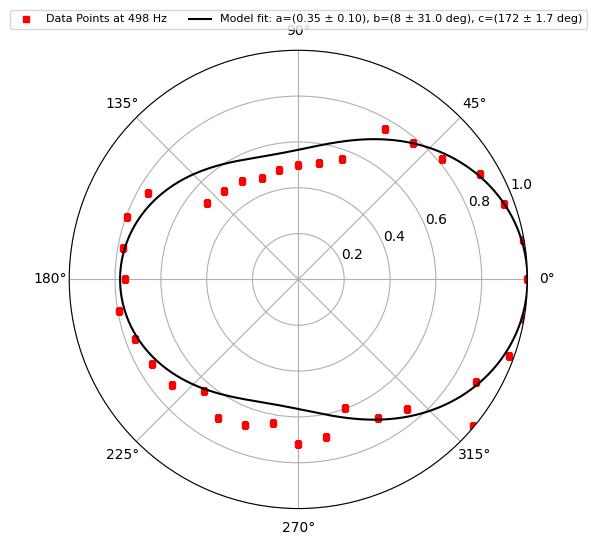

In [58]:
"""
Fit of the antenna polar distribution with |f(theta)|^2 (raw data, no background subtraction).
    f(theta) = 1 + 2 a e^{ib} cos(c - KDZ*cos(theta))        a = A1/A0, b = (phi1+phi2)/2, c = (phi1-phi2)/2
    |f|^2    = 1 + 4a cos(b) cos(c - x) + 4a^2 cos^2(c - x),  x = KDZ*cos(theta)
Free parameters: a, b, c.   Angle 0 = array axis, so the data are shifted by ANGLE_SHIFT_DEG
(-90 puts the main lobe on the axis, as in the paper convention).
"""

ANGLE_SHIFT_DEG = -90     # use 0 to fit the data exactly as measured
KDZ = np.pi / 4             # k*dz  (pi/4 <-> array separation = lambda/4)

angles_deg = np.arange(0, 360, 10) + ANGLE_SHIFT_DEG       # 360 deg = 0 deg point, dropped
amp = np.array([720, 700, 600, 700, 740, 1000, 900, 980, 1004, 1002, 1000, 960, 920, 820,
                780, 760, 560, 520, 500, 488, 472, 496, 504, 520, 760, 800, 780, 760, 800,
                760, 740, 720, 640, 700, 680, 640], float)
theta = np.radians(angles_deg)
y = amp / amp.max()

tf = np.linspace(0, 2 * np.pi, 3600, endpoint=False)

def intensity(t, a, b, c):
    x = KDZ * np.cos(t)
    f = 1+ 4*a*np.cos(b)*np.cos(c - x) + 4*a**2*np.cos(c - x)**2
    return np.sqrt(np.clip(f, 0, None))  # clip to avoid sqrt of negative numbers

def model(t, a, b, c):
    return intensity(t, a, b, c) / intensity(tf, a, b, c).max()

# multi-start least squares (first start = your Desmos values a=0.2, b=20 rad, c=0.5 rad)
rng = np.random.default_rng(1)
starts = [[0.2, 20 % (2*np.pi), 0.5]] + [[rng.uniform(0.05, 3), rng.uniform(-np.pi, np.pi),
                                           rng.uniform(-np.pi, np.pi)] for _ in range(300)]
best = None
for q0 in starts:
    r = least_squares(lambda q: model(theta, *q) - y, q0, bounds=([1e-3, -8, -8], [6, 8, 8]))
    if best is None or r.cost < best.cost:
        best = r
a, b, c = best.x
N, npar, ssr = len(y), 3, 2 * best.cost
cov = np.linalg.inv(best.jac.T @ best.jac) * ssr / (N - npar)
ea, eb, ec = np.sqrt(np.diag(cov))
deg = lambda r: np.degrees(r) % 360

print(f"a = A1/A0         = {a:.2f} +/- {ea:.2f}")
# the model depends on b only through cos(b): near b = 0 or 180 deg its error bar is meaningless
b_err = f"+/- {np.degrees(eb):.0f} deg" if np.degrees(eb) < 90 else "(poorly constrained: only cos b matters)"
print(f"b = (phi1+phi2)/2 = {deg(b):.0f} {b_err}")
print(f"c = (phi1-phi2)/2 = {deg(c):.0f} +/- {np.degrees(ec):.0f} deg")
print(f"phi1 = {deg(b+c):.0f} deg, phi2 = {deg(b-c):.0f} deg, phi1-phi2 = {deg(2*c):.0f} deg")
print(f"rms residual = {np.sqrt(ssr/N):.3f}")

tt = np.linspace(0, 2 * np.pi, 720)
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"projection": "polar"})
ax.plot(theta, y, "rs", ms=5, label="Data Points at 498 Hz")
ax.plot(tt, model(tt, a, b, c), "k-", label=f"Model fit: a=({a:.2f} ± {ea:.2f}), b=({deg(b):.0f} ± {np.degrees(eb):.1f} deg), c=({deg(c):.0f} ± {np.degrees(ec):.1f} deg)")
ax.set_theta_zero_location("E"); ax.set_theta_direction(1)
ax.set_rlim(0, 1); ax.set_rticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.1), ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

a = A1/A0 = 0.51 +/- 0.01
b = (phi1+phi2)/2 = 172 +/- 0.5 deg
c = (phi1-phi2)/2 = 2 +/- 0.4 deg  
phi1 = 174 deg, phi2 = 171 deg
rms residual = 0.054


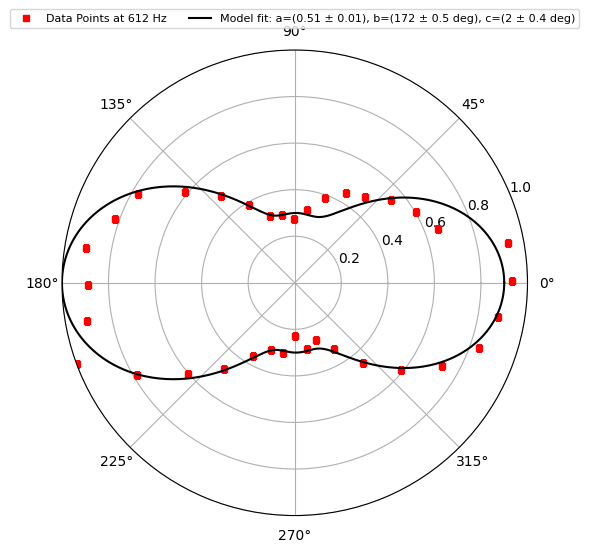

In [65]:
"""
Fit of the polar distribution (612 Hz) with the three-source model, in the form used in Desmos:
    f(theta)  = 1 + 2a e^{ib} cos(c - KDZ*cos(theta))
    |f|^2     = 1 + 4a cos(b) cos(c - x) + 4a^2 cos^2(c - x),   x = KDZ*cos(theta)
with a = A1/A0, b = (phi1+phi2)/2, c = (phi1-phi2)/2.
The measured voltage is an amplitude, so |f| (normalised to its maximum) is fitted -- no background subtraction.
Free parameters: a, b, c.
"""

KDZ = np.pi / 3.3        

angles_deg = np.arange(0, 360, 10)
angles_deg = angles_deg +20.5
amp = np.array([11.6,10.6,9.6,8.4,7.8,6.8,5.6,4.8,5.2,5.4,6.8,8.6,10.8,
                       13.6,14.4,16,15.6,16,17.6,13.8,10.6,8.4,6.4,5.4,5.4,4,
                       5.12,4.6,5.8,8,10.4,12.8,14.8,15.6,16.4,16.4])
theta = np.radians(angles_deg)
y = amp / amp.max()

tf = np.linspace(0, 2 * np.pi, 3600, endpoint=False)

def mag(t, a, b, c):
    x = KDZ * np.cos(t)
    f2 = 1 + 4*a*np.cos(b)*np.cos(c - x) + 4*a**2*np.cos(c - x)**2
    return np.sqrt(np.clip(f2, 0, None))

def model(t, a, b, c):
    return mag(t, a, b, c) / mag(tf, a, b, c).max()

def fit(n_start=200, seed=1):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_start):
        q0 = [rng.uniform(0.1, 3), rng.uniform(-np.pi, np.pi), rng.uniform(-np.pi, np.pi)]
        r = least_squares(lambda q: model(theta, *q) - y, q0, bounds=([0, -8, -8], [6, 8, 8]))
        if best is None or r.cost < best.cost:
            best = r
    return best

best = fit()
a, b, c = best.x
ssr_min, N, npar = 2 * best.cost, len(y), 3
phi1, phi2 = b + c, b - c
d = lambda r: np.degrees(r) % 360

# 1-sigma parameter uncertainties from the Jacobian (scaled by the residual scatter)
J = best.jac
cov = np.linalg.inv(J.T @ J) * ssr_min / (N - npar)
ea, eb, ec = np.sqrt(np.diag(cov))

print(f"a = A1/A0 = {a:.2f} +/- {ea:.2f}")
print(f"b = (phi1+phi2)/2 = {d(b):.0f} +/- {np.degrees(eb):.1f} deg")
print(f"c = (phi1-phi2)/2 = {d(c):.0f} +/- {np.degrees(ec):.1f} deg  ")
print(f"phi1 = {d(phi1):.0f} deg, phi2 = {d(phi2):.0f} deg")
print(f"rms residual = {np.sqrt(ssr_min/N):.3f}")

tt = np.linspace(0, 2 * np.pi, 720)
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"projection": "polar"})
Model_fit = f"Model fit: a=({a:.2f} ± {ea:.2f}), b=({d(b):.0f} ± {np.degrees(eb):.1f} deg), c=({d(c):.0f} ± {np.degrees(ec):.1f} deg)"
ax.plot(theta, y, "rs", ms=5, label="Data Points at 612 Hz")
ax.plot(tt, model(tt, *best.x), "k-", label=Model_fit)
ax.set_theta_zero_location("E"); ax.set_theta_direction(1)
ax.set_rlim(0, 1); ax.set_rticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.1), ncol=2, fontsize=8)
plt.tight_layout(); plt.show()